# dFBA with E. coli dataset

In [1]:
# check environment should be:
"""
Python version: 3.10.18
TF version: 2.16.2
Keras version: 3.9.2
NumPy version: 1.23.5
CobraPy version: 0.29.1
"""

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import tensorflow as tf
import utils
import data
import model
import plot
import sys
import cobra

print("Python version:", sys.version)
print("TF version:", tf.__version__)
print("Keras version:", tf.keras.__version__)
print("NumPy version:", np.__version__)
print("CobraPy version:", cobra.__version__)
print("Executable:", sys.executable)
print("Physical GPUs:", tf.config.list_physical_devices('GPU'))

TF version: 2.16.2
Keras version: 3.9.2
/Users/jean-loup-faulon/miniforge3/envs/M4/bin/python
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# dFBA benchmark with grid search for upper media uptake bounds

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
from sklearn.metrics import r2_score

import data
import utils
import plot
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="cobra")

# -----------------------------
# Config
# -----------------------------
folder    = './'
file_name = 'OD_20'
media_file       = folder + 'data/' + 'media_20.csv'
od_file          = folder + 'data/' + file_name + '.csv'
cobra_model_file = folder + 'data/' + 'iML1515_duplicated.xml'
biomass_rxn_id   = 'BIOMASS_Ec_iML1515_core_75p37M'
run_name         = f'{file_name}_dFBA'
OD = True

# -----------------------------
# 1) Build full inputs for dFBA
# -----------------------------
(
    times,
    metabolite_ids,
    experiment_array,   # shape (Z, T*k) flattened
    dev_array,          # shape (Z, T) or None
    exp_ids,
    Stoichiometry,
    Transport,
    rxn_ids,
) = data.build_dfba_inputs(
    media_file       = media_file,
    od_file          = od_file,
    cobra_model_file = cobra_model_file,
    biomass_rxn_id   = biomass_rxn_id,
    verbose          = False,
)

Z, flat_dim = experiment_array.shape
k = len(metabolite_ids)
T = len(times)

if flat_dim != T * k:
    raise ValueError(
        f"experiment_array second dim = {flat_dim}, "
        f"but T * k = {T} * {k} = {T*k}. "
        "Check build_dfba_inputs / prepare_experiment_array."
    )

# reshape to (Z, T, k)
conc_array = experiment_array.reshape(Z, T, k)

print(f"[dFBA] conc_array shape = {conc_array.shape}")
print(f"[dFBA] #experiments (media) Z = {Z}")
print(f"[dFBA] #time points T       = {T}")
print(f"[dFBA] #metabolites k       = {k}")

# -----------------------------
# 1b) Build ex_ids and select only metabolites that have a transport reaction
# -----------------------------
ex_met_idx = []  # indices of metabolites with a linked exchange reaction
ex_ids     = []  # corresponding reaction IDs (to pass to predict_dFBA)

for m_idx, met in enumerate(metabolite_ids):
    nz = np.where(Transport[m_idx] != 0)[0]
    if nz.size == 0:
        # this metabolite has no transport / exchange reaction in Transport
        continue
    j = nz[0]  # take the first nonzero as its exchange/transport reaction
    ex_met_idx.append(m_idx)
    ex_ids.append(rxn_ids[j])

ex_met_idx = np.array(ex_met_idx, dtype=int)

print(f"[dFBA] #external metabolites with exchange rxn = {len(ex_met_idx)}")
print(f"[dFBA] first few ex_ids: {ex_ids[:5]}")

# -----------------------------
# 2) Run dFBA for all media
# -----------------------------
# initial medium composition C(t=0) for each experiment,
# but restricted to metabolites that have an exchange reaction
media_conc_array_full = conc_array[:, 0, :]                 # shape (Z, k)
media_conc_array      = media_conc_array_full[:, ex_met_idx]  # shape (Z, k_ex)
Z = media_conc_array.shape[0]
T = len(times)
pred_biomass = np.zeros((Z, T))

# Reference biomass trajectories (M28 OD data → BIOMASS column)
bio_idx = metabolite_ids.index('BIOMASS')
Ref_bio = conc_array[:, :, bio_idx]   # (Z, T)

# --- Grid over alpha and beta ---
alpha_grid = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
beta_grid  = [0.001, 0.005, 0.01, 0.015, 0.02]

best_R2         = -np.inf
best_alpha      = None
best_beta       = None
best_pred_bio   = None   # shape (Z, T)
best_R2_per_exp = None   # shape (Z,)

# T already defined as len(times)
for alpha in alpha_grid:
    for beta in beta_grid:
        # Build uptake_scaler for this (alpha, beta)
        # media_conc_array has shape (Z, k_ex+1) with last col = biomass
        k_ex = media_conc_array.shape[1] - 1
        uptake_scaler = alpha * np.ones(k_ex)
        uptake_scaler[0] = beta  # glc__D_e
        uptake_scaler[1] = beta  # xyl__D_e
        uptake_scaler[2] = beta  # succ_e

        # Container for predictions with this (alpha, beta)
        pred_biomass_current = np.zeros((Z, T))
        R2_current = np.zeros(Z)

        for z in range(Z):
            pred_biomass_current[z] = data.predict_dFBA(
                cobra_model_file=cobra_model_file,
                biomass_rxn_id=biomass_rxn_id,
                media_conc=media_conc_array[z, :-1],   # shape (k_ex,)
                ex_ids=ex_ids[:-1],                    # list length k_ex
                time_points=times,
                uptake_scaler=uptake_scaler,
                volume=1.0,
                X_init=media_conc_array[z, -1]        # initial biomass
            )

            # R² for experiment z
            ref_z  = Ref_bio[z]               # (T,)
            pred_z = pred_biomass_current[z]  # (T,)
            R2_current[z] = utils.r2_growth_curve_single(pred_z, ref_z, OD=OD)

        mean_R2, median_R2 = np.mean(R2_current), np.median(R2_current)
        print(f"[dFBA] alpha={alpha:.4f}, beta={beta:.4f} -> mean R2 = {mean_R2:.4f} median R2 {median_R2:.4f}")

        # Keep best configuration
        if mean_R2 > best_R2:
            best_R2         = mean_R2
            best_alpha      = alpha
            best_beta       = beta
            best_pred_bio   = pred_biomass_current.copy()
            best_R2_per_exp = R2_current.copy()

# After grid search, use the best results
pred_biomass = best_pred_bio        # (Z, T), predictions for best (alpha,beta)
R2          = best_R2_per_exp       # (Z,)
R2dev       = np.zeros_like(R2)     # no std here, but keep interface

print(
    f"[dFBA] BEST (alpha, beta) = ({best_alpha:.3f}, {best_beta:.3f})  "
    f"R2 = {np.mean(R2):.2f}±{np.std(R2):.2f}  "
    f"R2dev = {np.mean(R2dev):.2f}  "
    f"Median = {np.median(R2):.2f}"
)



[dFBA] conc_array shape = (20, 20, 29)
[dFBA] #experiments (media) Z = 20
[dFBA] #time points T       = 20
[dFBA] #metabolites k       = 29
[dFBA] #external metabolites with exchange rxn = 29
[dFBA] first few ex_ids: ['EX_glc__D_e_i', 'EX_xyl__D_e_i', 'EX_succ_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i']
[dFBA] alpha=0.1000, beta=0.0010 -> mean R2 = 0.0211 median R2 0.0000
[dFBA] alpha=0.1000, beta=0.0050 -> mean R2 = 0.0211 median R2 0.0000
[dFBA] alpha=0.1000, beta=0.0100 -> mean R2 = 0.0211 median R2 0.0000
[dFBA] alpha=0.1000, beta=0.0150 -> mean R2 = 0.0374 median R2 0.0000
[dFBA] alpha=0.1000, beta=0.0200 -> mean R2 = 0.0872 median R2 0.0000
[dFBA] alpha=0.2000, beta=0.0010 -> mean R2 = 0.1424 median R2 0.0000
[dFBA] alpha=0.2000, beta=0.0050 -> mean R2 = 0.1568 median R2 0.0000
[dFBA] alpha=0.2000, beta=0.0100 -> mean R2 = 0.1848 median R2 0.0306
[dFBA] alpha=0.2000, beta=0.0150 -> mean R2 = 0.2338 median R2 0.1444
[dFBA] alpha=0.2000, beta=0.0200 -> mean R2 = 0.2804 median R2 0.2730

[dFBA] conc_array shape = (280, 20, 29)
[dFBA] #experiments (media) Z = 280
[dFBA] #time points T       = 20
[dFBA] #metabolites k       = 29
[dFBA] #external metabolites with exchange rxn = 29
[dFBA] first few ex_ids: ['EX_glc__D_e_i', 'EX_xyl__D_e_i', 'EX_succ_e_i', 'EX_ala__L_e_i', 'EX_arg__L_e_i']
[dFBA] Model: M28_OD_20_dFBA  R2 = 0.34±0.28  R2dev = 0.00  Median = 0.34


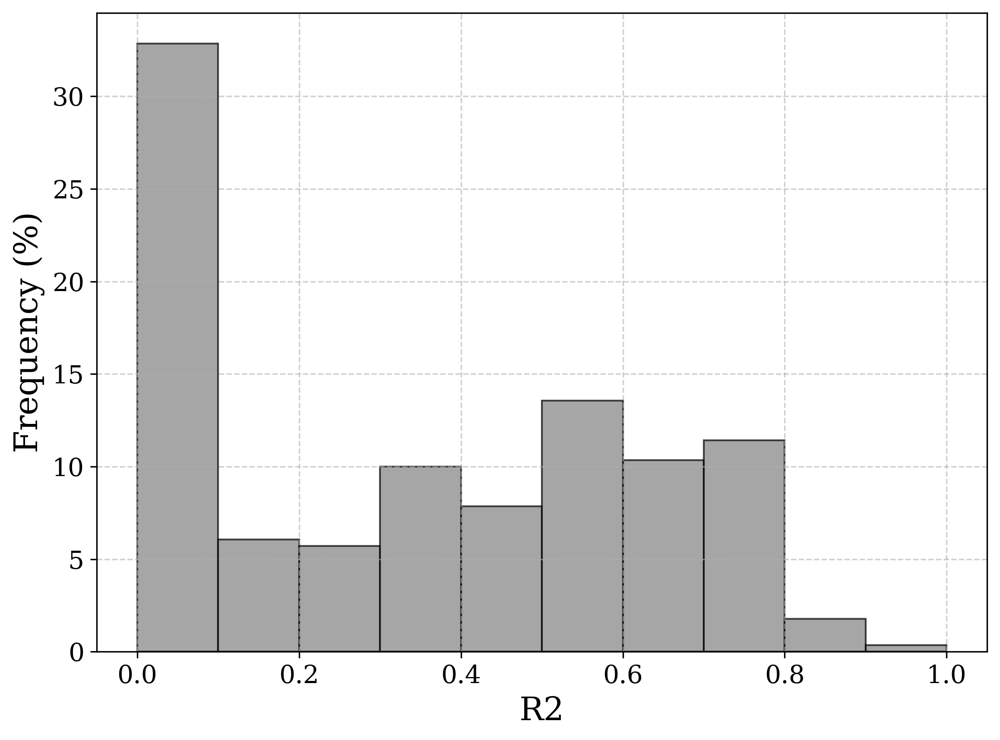

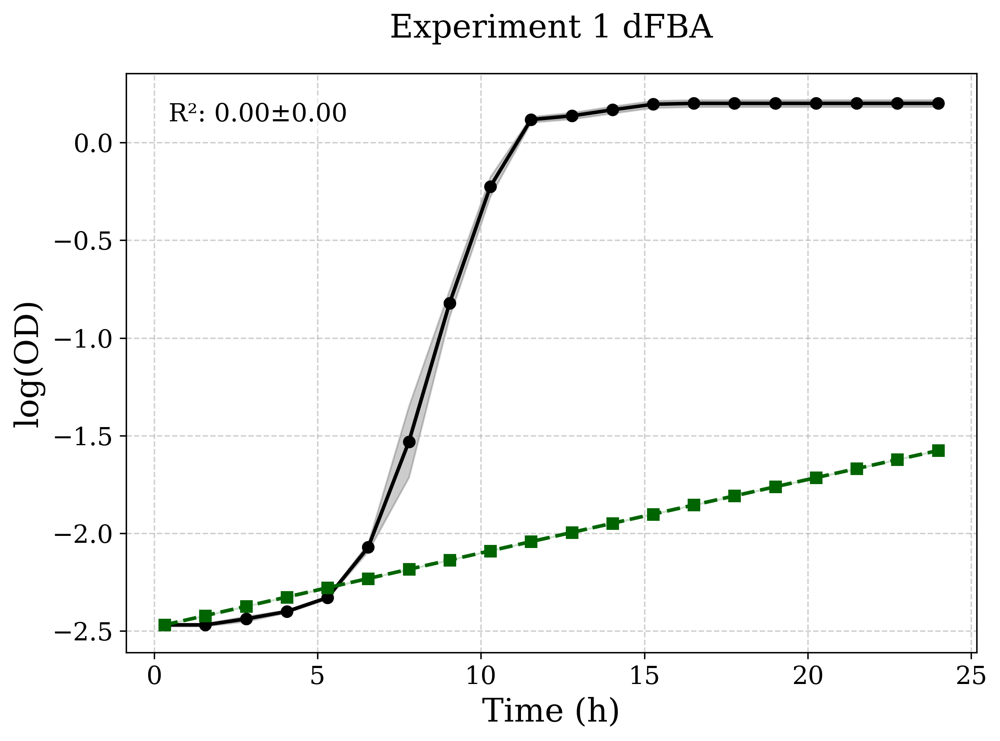

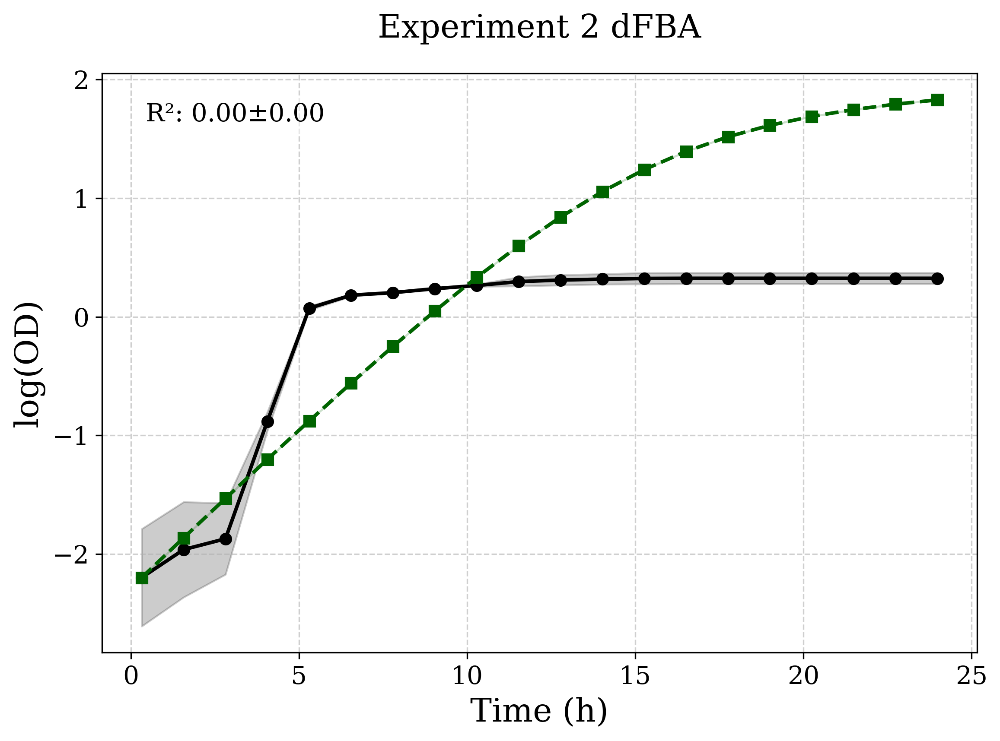

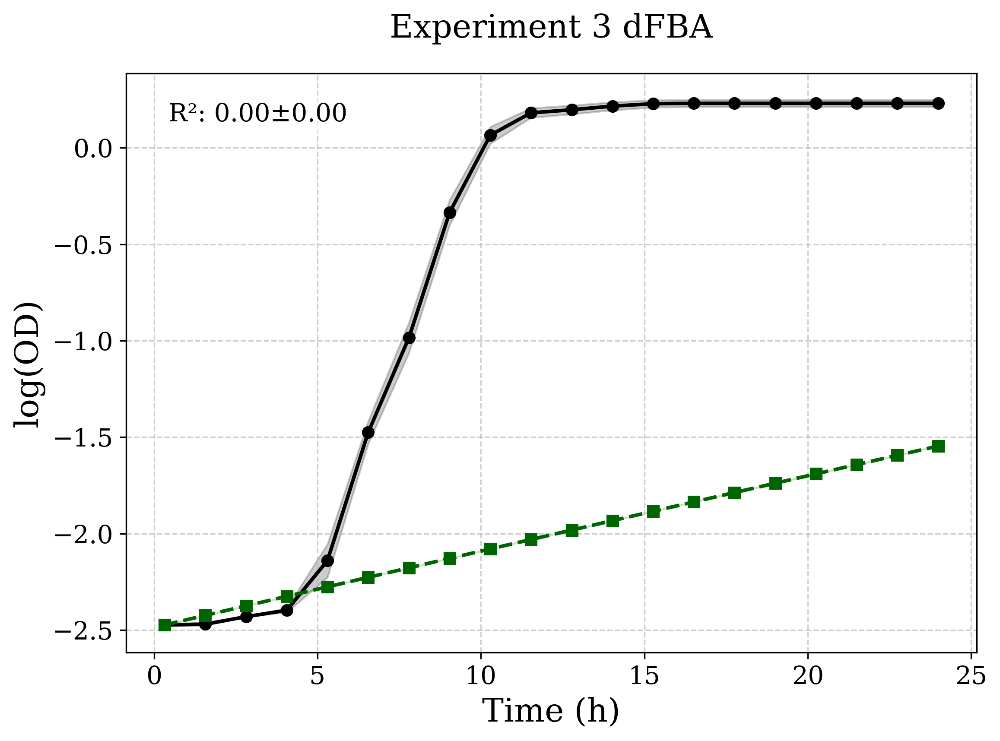

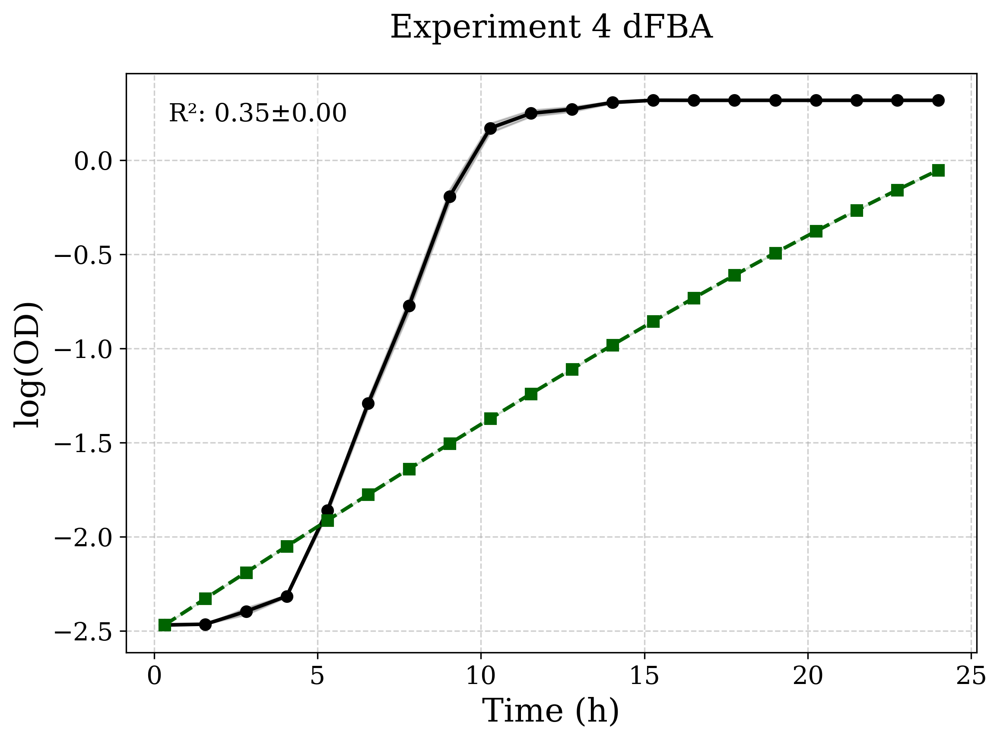

...

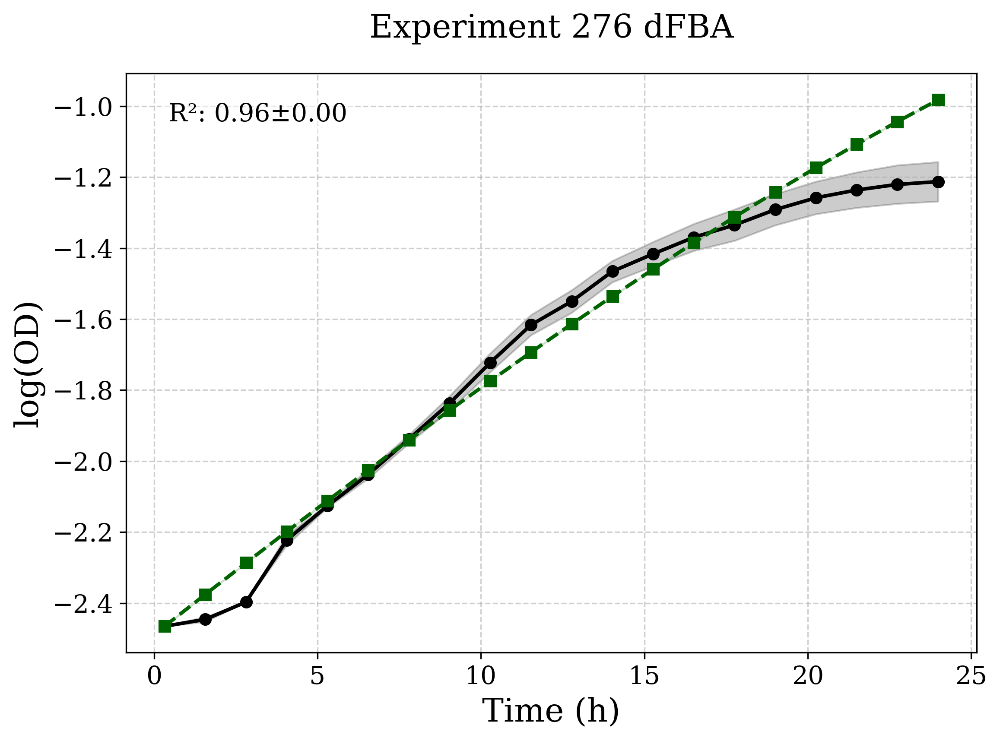

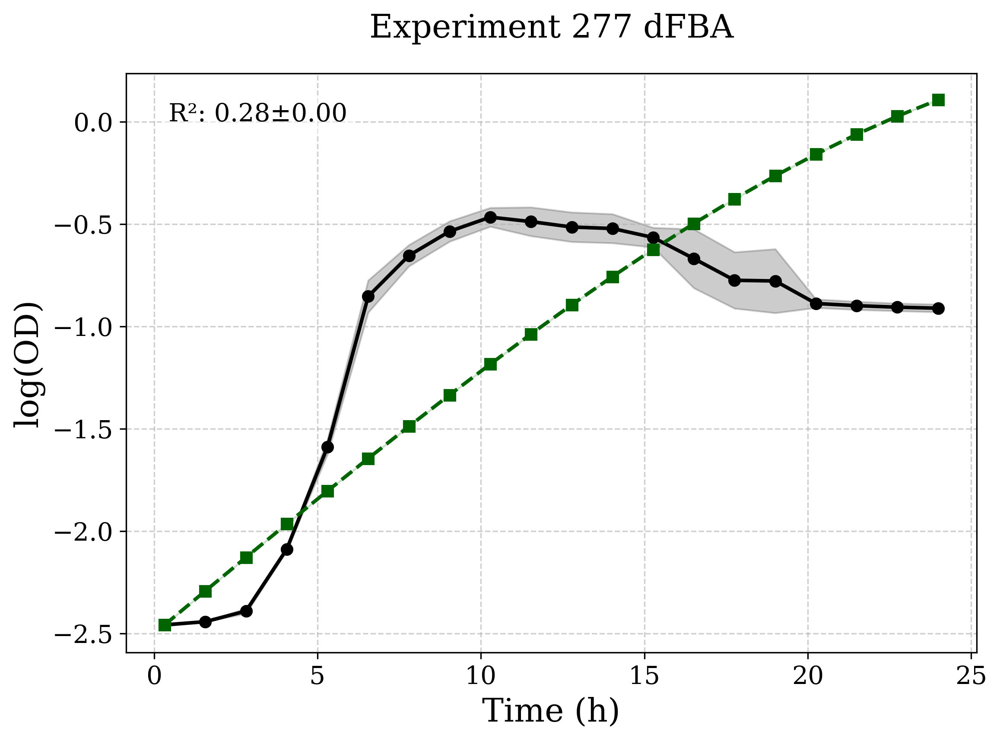

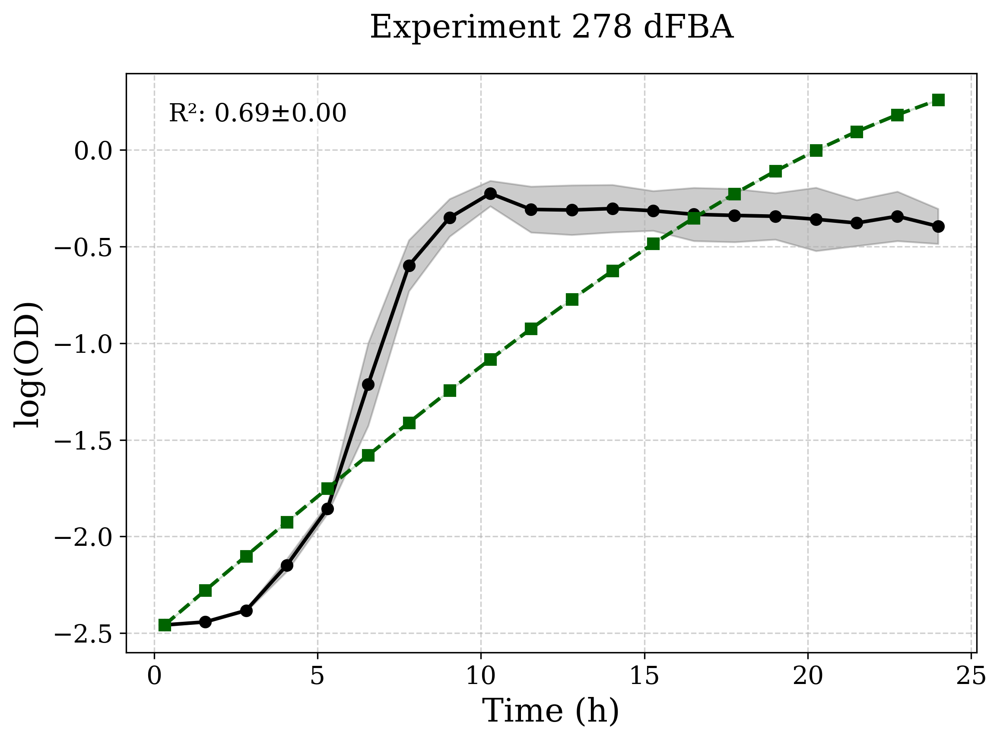

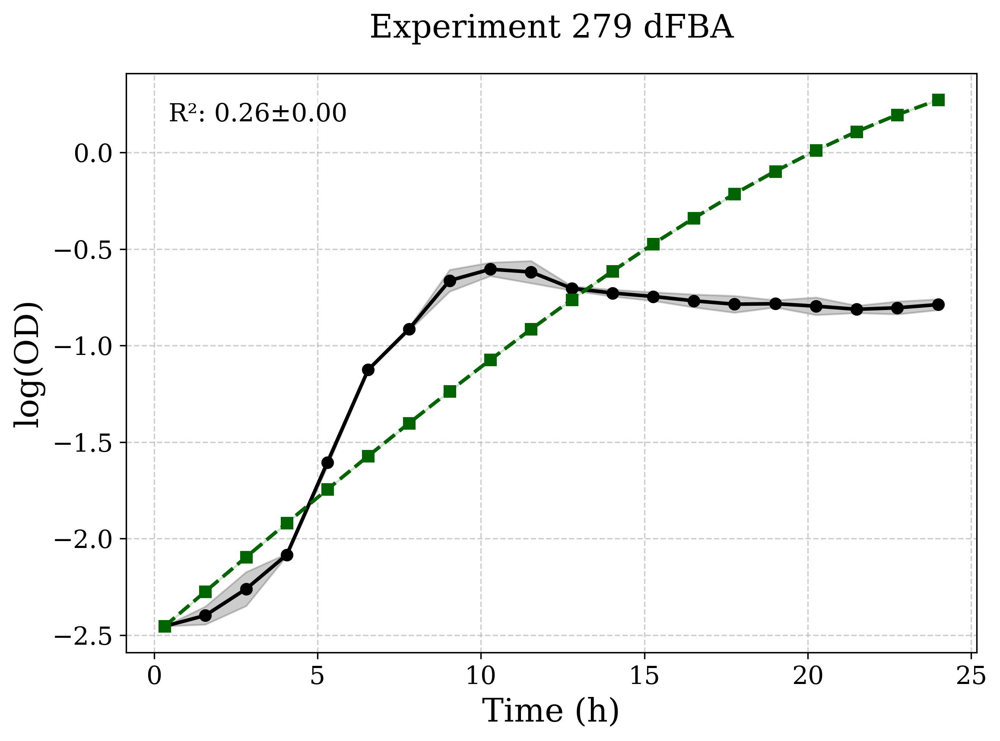

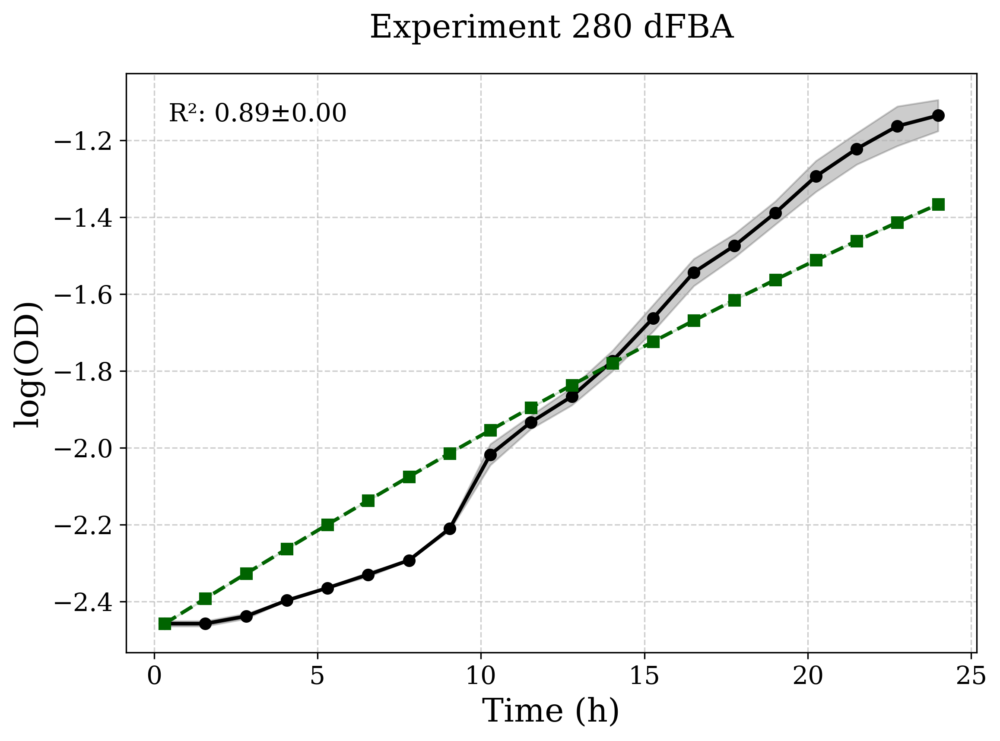

In [6]:
# dFBA benchmark on M28_conc_20 

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
from sklearn.metrics import r2_score

import dFBA
import utils
import plot
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="cobra")

# -----------------------------
# Config
# -----------------------------
folder    = './'
file_name = 'M28_conc_20'
media_file       = folder + 'data/' + 'M28_media.csv'
od_file          = folder + 'data/' + file_name + '.csv'
cobra_model_file = folder + 'data/' + 'iML1515_duplicated.xml'
biomass_rxn_id   = 'BIOMASS_Ec_iML1515_core_75p37M'
run_name         = f'{file_name}_dFBA'
OD = True

# -----------------------------
# 1) Build full inputs for dFBA
# -----------------------------
(
    times,
    metabolite_ids,
    experiment_array,   # shape (Z, T*k) flattened
    dev_array,          # shape (Z, T) or None
    exp_ids,
    Stoichiometry,
    reaction_KO,
    Transport,
    rxn_ids,
) = dFBA.build_dfba_inputs(
    media_file       = media_file,
    od_file          = od_file,
    cobra_model_file = cobra_model_file,
    biomass_rxn_id   = biomass_rxn_id,
    verbose          = False,
)

Z, flat_dim = experiment_array.shape
k = len(metabolite_ids)
T = len(times)

if flat_dim != T * k:
    raise ValueError(
        f"experiment_array second dim = {flat_dim}, "
        f"but T * k = {T} * {k} = {T*k}. "
        "Check build_dfba_inputs / prepare_experiment_array."
    )

# reshape to (Z, T, k)
conc_array = experiment_array.reshape(Z, T, k)

print(f"[dFBA] conc_array shape = {conc_array.shape}")
print(f"[dFBA] #experiments (media) Z = {Z}")
print(f"[dFBA] #time points T       = {T}")
print(f"[dFBA] #metabolites k       = {k}")

# -----------------------------
# 1b) Build ex_ids and select only metabolites that have a transport reaction
# -----------------------------
ex_met_idx = []  # indices of metabolites with a linked exchange reaction
ex_ids     = []  # corresponding reaction IDs (to pass to predict_dFBA)

for m_idx, met in enumerate(metabolite_ids):
    nz = np.where(Transport[m_idx] != 0)[0]
    if nz.size == 0:
        # this metabolite has no transport / exchange reaction in Transport
        continue
    j = nz[0]  # take the first nonzero as its exchange/transport reaction
    ex_met_idx.append(m_idx)
    ex_ids.append(rxn_ids[j])

ex_met_idx = np.array(ex_met_idx, dtype=int)

print(f"[dFBA] #external metabolites with exchange rxn = {len(ex_met_idx)}")
print(f"[dFBA] first few ex_ids: {ex_ids[:5]}")

# -----------------------------
# 2) Run dFBA for all media
# -----------------------------
# initial medium composition C(t=0) for each experiment,
# but restricted to metabolites that have an exchange reaction
media_conc_array_full = conc_array[:, 0, :]  # shape (Z, k)
media_conc_array      = media_conc_array_full[:, ex_met_idx]  # shape (Z, k_ex)
Z = media_conc_array.shape[0]
T = len(times)
pred_biomass = np.zeros((Z, T))

# Reference biomass trajectories (M28 data, BIOMASS column in gDW/L)
bio_idx = metabolite_ids.index('BIOMASS')
Ref_bio = conc_array[:, :, bio_idx]   # (Z, T)

# Run dFBA with scaler for media uptake
alpha = 0.2000
beta = 0.0200
uptake_scaler = alpha * np.ones(media_conc_array.shape[1]-1)
uptake_scaler[0] = beta # glc__D_e
uptake_scaler[1] = beta # xyl__D_e
uptake_scaler[2] = beta # succ_e
R2 = np.zeros(Z)

for z in range(Z):
    pred_biomass[z] = dFBA.predict_dFBA(
        cobra_model_file=cobra_model_file,
        biomass_rxn_id=biomass_rxn_id,
        media_conc=media_conc_array[z,:-1],   # shape (k_ex,)
        ex_ids=ex_ids[:-1],                   # list length k_ex
        time_points=times,
        uptake_scaler=uptake_scaler,
        volume=1.0,
        X_init=media_conc_array[z,-1] # initial biomass 
    )

    # Compute R² for this experiment z
    ref_z  = Ref_bio[z]      # (T,)
    pred_z = pred_biomass[z] # (T,)
    R2[z] = utils.r2_growth_curve_single(pred_z, ref_z, OD=OD)
    # print(f"     R²(z={z}) = {R2[z]:.3f}")
R2dev = np.zeros_like(R2)
print(
    f"[dFBA] Model: {run_name}  "
    f"R2 = {np.mean(R2):.2f}±{np.std(R2):.2f}  "
    f"R2dev = {np.mean(R2dev):.2f}  "
    f"Median = {np.median(R2):.2f}"
)


# -----------------------------
# 3) Build Pred / Ref arrays for plotting
# -----------------------------
# shape to (N_iter, Z, T, n_met) with N_iter=1, n_met=1
Pred = pred_biomass[np.newaxis, ..., np.newaxis]  # (1, Z, T, 1)
Ref  = Ref_bio[np.newaxis,    ..., np.newaxis]    # (1, Z, T, 1)

# -----------------------------
# 4) R² histogram
# -----------------------------
title = f"R2 Histogram dFBA ({file_name})"
plot.plot_similarity_distribution(title, R2, save="./figure")

# -----------------------------
# 5) Plot dFBA vs reference growth curves
# -----------------------------
train_time_steps = 0  # no training in dFBA

plot.plot_predicted_reference_growth_curve(
    times            = times,
    Pred             = Pred,
    Ref              = Ref,
    val_dev          = dev_array,          # or None if you prefer
    OD               = OD,
    R2               = R2,
    R2dev            = R2dev,
    train_time_steps = train_time_steps,
    experiment_ids   = exp_ids,
    run_name         = run_name,
    train_test_split = 'dFBA',
    save             = "./figure",
)
